# Étape 1.3 — Préparation des données pour la modélisation

> **Énoncé (1.3)** : encoder les variables qualitatives ; normaliser ou standardiser les variables quantitatives si nécessaire ; évaluer si les variables peuvent être utilisées directement ou si une transformation est nécessaire ; proposer et justifier un regroupement, une discrétisation ou une transformation pour chaque variable concernée ; présenter le jeu de données final.

Ce notebook reprend le script `etape_1_3_preparation.py` : mêmes calculs, mêmes résultats, enregistrés dans `resultats/`. Les décisions et l'interprétation des résultats sont détaillées dans [README.md](README.md) (version LaTeX : `README.tex`).

**Contenu de l'étape :**


1. Évaluation : chaque variable est-elle utilisable telle quelle (modalités rares, asymétrie) ?
2. Regroupement des modalités rares des variables qualitatives.
3. Discrétisation des variables continues en classes (variables tarifaires des GLM).
4. Transformation logarithmique des variables quantitatives très asymétriques.
5. Encodage : binaire 0/1, codes ordinaux, indicatrices (one-hot).
6. Standardisation (centrage-réduction) de la matrice utilisée par le K-means.
7. Jeu de données final et rôle de chaque variable.


## Préparation

Bibliothèques, module commun du projet, dossier de résultats et journal.

In [1]:
import sys
from pathlib import Path

# Le notebook s'exécute dans le dossier de l'étape : on remonte jusqu'à la racine du projet
RACINE_PROJET = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "commun" / "outils.py").exists())
sys.path.insert(0, str(RACINE_PROJET))

import numpy as np
import pandas as pd

from commun import outils as o

RES = o.dossier_resultats("1.3")
log = o.Journal(RES, "Étape 1.3 — Préparation pour la modélisation")
plt = o.style_graphique()
C = o.COULEURS
BLEU = o.SERIES[0]

df = o.lire_donnees("aberrantes")
n = len(df)
log(f"Entrée : {o.DONNEES['aberrantes'].relative_to(o.RACINE)} — {n} individus")

QUANTI = ["age", "taille_menage", "nb_actifs_menage", "budget_alim", "budget_sante", "budget_elec",
          "anciennete_emploi", "distance_travail", "heures_jour", "jours_semaine"]
NOMINALES = ["sexe", "lien_chef_menage", "statut_pro", "statut_matrimonial", "secteur",
             "statut_residence", "source_eau", "source_electricite", "energie_cuisine",
             "type_toilette", "transport_travail", "epargne", "dettes", "maladie_chronique",
             "lunettes", "renoncement_soins"]
ORDINALES = ["niveau_etude", "revenu", "effort_physique", "duree_effort", "pb_sante_travail",
             "arret_maladie", "impact_travail_sante", "repos_recent", "interet_couverture", "dentiste"]
SEUIL_RARE = 3.0       # % : une modalité plus rare est regroupée
SEUIL_ASYMETRIE = 1.0  # |asymétrie| au-delà de laquelle on teste une transformation log

# Étape 1.3 — Préparation pour la modélisation


Entrée : partie1_donnees\1.2_aberrantes\resultats\donnees_sans_aberrantes.csv — 4074 individus


## 1. Évaluation des variables

In [2]:
log.section("1. Les variables sont-elles utilisables directement ?")
evaluation = []
for v in NOMINALES + ORDINALES:
    parts = 100 * df[v].value_counts(normalize=True)
    evaluation.append({"variable": v, "type": "nominale" if v in NOMINALES else "ordinale",
                       "modalites": len(parts), "plus_petite_modalite": parts.idxmin(),
                       "pct_plus_petite": parts.min(),
                       "modalites_rares": int((parts < SEUIL_RARE).sum())})
for v in QUANTI:
    asym = df[v].skew()
    evaluation.append({"variable": v, "type": "quantitative", "asymetrie": asym,
                       "asymetrie_log": np.log1p(df[v]).skew() if abs(asym) > SEUIL_ASYMETRIE else np.nan})
evaluation = pd.DataFrame(evaluation)
o.sauver_table(evaluation, RES, "evaluation_variables")
log(f"Qualitatives : modalités de moins de {SEUIL_RARE:g} % des individus")
log.table(evaluation[evaluation.type != "quantitative"][["variable", "type", "modalites",
          "plus_petite_modalite", "pct_plus_petite", "modalites_rares"]], index=False, floatfmt=".1f")
log("Quantitatives : asymétrie après traitement des valeurs aberrantes")
log.table(evaluation[evaluation.type == "quantitative"][["variable", "asymetrie", "asymetrie_log"]],
          index=False, floatfmt=".2f");


## 1. Les variables sont-elles utilisables directement ?

Qualitatives : modalités de moins de 3 % des individus


variable,type,modalites,plus_petite_modalite,pct_plus_petite,modalites_rares
sexe,nominale,2.0,Homme,42.4,0.0
lien_chef_menage,nominale,5.0,Parent,1.0,2.0
statut_pro,nominale,3.0,Salarié et indépendant,0.9,1.0
statut_matrimonial,nominale,4.0,Divorcé(e),5.1,0.0
secteur,nominale,25.0,Énergie,0.0,18.0
statut_residence,nominale,2.0,Locataire,47.8,0.0
source_eau,nominale,4.0,Branchement à domicile,2.9,1.0
source_electricite,nominale,5.0,Bougie,2.7,1.0
energie_cuisine,nominale,4.0,Gaz,0.0,2.0
type_toilette,nominale,5.0,Autre,0.1,2.0


Quantitatives : asymétrie après traitement des valeurs aberrantes


variable,asymetrie,asymetrie_log
age,0.22,
taille_menage,0.68,
nb_actifs_menage,0.85,
budget_alim,-0.37,
budget_sante,0.89,
budget_elec,0.91,
anciennete_emploi,0.93,
distance_travail,2.17,0.60
heures_jour,0.67,
jours_semaine,-1.53,-2.78


## 2. Regroupement des modalités

In [3]:
log.section("2. Regroupement des modalités rares")
GROUPES = {
    "secteur": {
        "Agriculture, élevage": ["Agriculture", "Élevage, pêche"],
        "Commerce": ["Commerce", "Distribution"],
        "Artisanat, industrie, BTP": ["Artisanat", "Agroalimentaire", "Matériaux de construction",
                                      "Textile", "Bâtiment", "Électronique", "Construction mécanique",
                                      "Métallurgie", "Industrie chimique", "Énergie",
                                      "Entretien, réparation"],
        "Services, transport": ["Transport", "Hôtellerie, restauration", "Services", "Informatique",
                                "Communication, médias", "Banque, finance", "Loisirs, tourisme"],
        "Éducation, santé": ["Éducation", "Santé"],
        "Autre": ["Autre"],
    },
    "lien_chef_menage": {"Chef de ménage": ["Chef de ménage"], "Conjoint(e)": ["Conjoint(e)"],
                         "Autre membre": ["Enfant", "Parent", "Frère/sœur"]},
    "statut_pro": {"Indépendant": ["Indépendant"], "Salarié": ["Salarié", "Salarié et indépendant"]},
    "statut_matrimonial": {"Marié(e)": ["Marié(e)"], "Célibataire": ["Célibataire"],
                           "Veuf(ve), divorcé(e)": ["Veuf(ve)", "Divorcé(e)"]},
    "source_eau": {"Borne fontaine": ["Borne fontaine"], "Branchement à domicile": ["Branchement à domicile"],
                   "Puits ou autre": ["Puits", "Autre"]},
    "source_electricite": {"Réseau JIRAMA": ["Réseau JIRAMA"], "Solaire": ["Solaire"],
                           "Pétrole, bougie, autre": ["Pétrole", "Bougie", "Autre"]},
    "energie_cuisine": {"Charbon, gaz, électricité": ["Charbon", "Gaz", "Électricité"], "Bois": ["Bois"]},
    "type_toilette": {"Latrines": ["Latrines"], "Chasse d'eau": ["Chasse d'eau"],
                      "Sèches ou aucune": ["Toilettes sèches", "Plein air", "Autre"]},
    "transport_travail": {"À pied": ["À pied"], "Travail à domicile": ["Travail à domicile"],
                          "Véhicule": ["Moto", "Transport en commun", "Vélo", "Voiture",
                                       "Taxi, taxi-moto", "Autre"]},
    # ordinales : les codes gardent l'échelle complète, les libellés sont regroupés
    "niveau_etude": {"Primaire ou moins": ["Analphabète", "Primaire"], "Collège": ["Collège"],
                     "Lycée": ["Lycée"], "Université": ["Université"]},
    "revenu": {"<100k": ["<100k"], "100-200k": ["100-200k"], "200-400k": ["200-300k", "300-400k"],
               ">400k": ["400-500k", "500k-1M", ">1M"]},
    "effort_physique": {"Parfois ou moins": ["Jamais", "Rarement", "Parfois"], "Souvent": ["Souvent"],
                        "Toujours": ["Toujours"]},
    "interet_couverture": {"Non": ["Pas du tout", "Plutôt non"], "Plutôt oui": ["Plutôt oui"],
                           "Tout à fait": ["Tout à fait"]},
}
ORDRE_GROUPES = {v: list(g) for v, g in GROUPES.items()}
final = df.copy()
lignes = []
for v, groupes in GROUPES.items():
    correspondance = {m: g for g, mods in groupes.items() for m in mods}
    inconnues = set(df[v].unique()) - set(correspondance)
    if inconnues:
        raise ValueError(f"{v} : modalités sans groupe {inconnues}")
    final[v] = df[v].map(correspondance)
    for g, mods in groupes.items():
        lignes.append({"variable": v, "groupe": g, "modalites_regroupees": ", ".join(mods),
                       "effectif": int((final[v] == g).sum()), "pct": 100 * (final[v] == g).mean()})
regroupements = pd.DataFrame(lignes)
o.sauver_table(regroupements, RES, "regroupements")
log.table(regroupements, index=False, floatfmt=".1f");


## 2. Regroupement des modalités rares



variable,groupe,modalites_regroupees,effectif,pct
secteur,"Agriculture, élevage","Agriculture, Élevage, pêche",1419,34.8
secteur,Commerce,"Commerce, Distribution",955,23.4
secteur,"Artisanat, industrie, BTP","Artisanat, Agroalimentaire, Matériaux de construction, Textile, Bâtiment, Électronique, Construction mécanique, Métallurgie, Industrie chimique, Énergie, Entretien, réparation",287,7.0
secteur,"Services, transport","Transport, Hôtellerie, restauration, Services, Informatique, Communication, médias, Banque, finance, Loisirs, tourisme",364,8.9
secteur,"Éducation, santé","Éducation, Santé",252,6.2
secteur,Autre,Autre,797,19.6
lien_chef_menage,Chef de ménage,Chef de ménage,2180,53.5
lien_chef_menage,Conjoint(e),Conjoint(e),1413,34.7
lien_chef_menage,Autre membre,"Enfant, Parent, Frère/sœur",481,11.8
statut_pro,Indépendant,Indépendant,3426,84.1


## 3. Discrétisation (classes)

In [4]:
log.section("3. Discrétisation des variables continues")
CLASSES = {
    "classe_age": ("age", [17, 24, 34, 44, 54, 120], ["18-24", "25-34", "35-44", "45-54", "55+"]),
    "classe_menage": ("taille_menage", [0, 2, 4, 6, 99], ["1-2", "3-4", "5-6", "7+"]),
    "classe_heures": ("heures_jour", [0, 6, 8, 10, 24], ["≤6 h", "7-8 h", "9-10 h", ">10 h"]),
    "classe_jours": ("jours_semaine", [0, 5.5, 6.5, 7], ["≤5 j", "6 j", "7 j"]),
    "classe_budget_sante": ("budget_sante", [-1, 0, 9.99, 10, 100], ["0 %", "1-9 %", "10 %", ">10 %"]),
    "classe_anciennete": ("anciennete_emploi", [-1, 4.99, 9.99, 19.99, 99],
                          ["<5 ans", "5-9 ans", "10-19 ans", "20 ans et +"]),
    "classe_distance": ("distance_travail", [-1, 0, 0.99, 2, 99], ["Domicile (0)", "<1 km", "1-2 km", ">2 km"]),
}
lignes = []
for nom, (source, bornes, etiquettes) in CLASSES.items():
    final[nom] = pd.cut(df[source], bins=bornes, labels=etiquettes).astype(str)
    eff = final[nom].value_counts()
    for e in etiquettes:
        lignes.append({"classe_variable": nom, "source": source, "classe": e,
                       "effectif": int(eff.get(e, 0)), "pct": 100 * eff.get(e, 0) / n})
    ORDRE_GROUPES[nom] = etiquettes
classes = pd.DataFrame(lignes)
o.sauver_table(classes, RES, "classes")
log("Bornes choisies pour obtenir des classes d'effectif suffisant (≥ 8 %) et lisibles :")
log.table(classes, index=False, floatfmt=".1f");


## 3. Discrétisation des variables continues

Bornes choisies pour obtenir des classes d'effectif suffisant (≥ 8 %) et lisibles :


classe_variable,source,classe,effectif,pct
classe_age,age,18-24,532,13.1
classe_age,age,25-34,1180,29.0
classe_age,age,35-44,1094,26.9
classe_age,age,45-54,879,21.6
classe_age,age,55+,389,9.5
classe_menage,taille_menage,1-2,383,9.4
classe_menage,taille_menage,3-4,1830,44.9
classe_menage,taille_menage,5-6,1454,35.7
classe_menage,taille_menage,7+,407,10.0
classe_heures,heures_jour,≤6 h,1575,38.7


## 4. Transformation

In [5]:
log.section("4. Transformation des variables asymétriques")
final["log_distance_travail"] = np.log1p(df["distance_travail"])
log(f"distance_travail : asymétrie {df.distance_travail.skew():.2f} -> log(1 + x) : "
    f"{final.log_distance_travail.skew():.2f}")
log("jours_semaine (asymétrie -1,53) : variable bornée et concentrée sur 6 ; pas de transformation,")
log("l'information est mieux résumée par ses classes (≤5 j / 6 j / 7 j).");


## 4. Transformation des variables asymétriques

distance_travail : asymétrie 2.17 -> log(1 + x) : 0.60
jours_semaine (asymétrie -1,53) : variable bornée et concentrée sur 6 ; pas de transformation,
l'information est mieux résumée par ses classes (≤5 j / 6 j / 7 j).


## 5. Encodage

In [6]:
log.section("5. Encodage des variables qualitatives")
codage, X = [], pd.DataFrame(index=final.index)
for v in ORDINALES:
    ordre = o.ORDRES[v]
    X[f"{v}_code"] = df[v].map({m: i for i, m in enumerate(ordre)})
    final[f"{v}_code"] = X[f"{v}_code"]
    codage.append({"colonne": f"{v}_code", "source": v, "encodage": "code ordinal",
                   "detail": " < ".join(f"{m}={i}" for i, m in enumerate(ordre))})
BINAIRES = {"femme": ("sexe", "Femme"), "salarie": ("statut_pro", "Salarié"),
            "proprietaire": ("statut_residence", "Propriétaire"), "epargne_oui": ("epargne", "Oui"),
            "dettes_oui": ("dettes", "Oui"), "chronique_oui": ("maladie_chronique", "Oui"),
            "lunettes_oui": ("lunettes", "Oui"), "renoncement_oui": ("renoncement_soins", "Oui"),
            "cuisine_bois": ("energie_cuisine", "Bois")}
for col, (source, modalite) in BINAIRES.items():
    X[col] = (final[source] == modalite).astype(int)
    codage.append({"colonne": col, "source": source, "encodage": "binaire 0/1",
                   "detail": f"1 = {modalite}"})
INDICATRICES = ["lien_chef_menage", "statut_matrimonial", "secteur", "source_eau",
                "source_electricite", "type_toilette", "transport_travail"]
for v in INDICATRICES:
    for g in ORDRE_GROUPES[v]:
        col = f"{v}={g}"
        X[col] = (final[v] == g).astype(int)
        codage.append({"colonne": col, "source": v, "encodage": "indicatrice (one-hot)",
                       "detail": f"1 = {g}"})
for v in QUANTI:
    source = "log_distance_travail" if v == "distance_travail" else v
    X[source] = final[source]
    codage.append({"colonne": source, "source": v, "encodage": "quantitative" +
                   (" (log 1+x)" if source != v else ""), "detail": ""})
log(f"Matrice encodée : {X.shape[1]} colonnes "
    f"({sum(c['encodage'] == 'code ordinal' for c in codage)} codes ordinaux, "
    f"{len(BINAIRES)} binaires, {sum(c['encodage'].startswith('indicatrice') for c in codage)} indicatrices, "
    f"{len(QUANTI)} quantitatives)");


## 5. Encodage des variables qualitatives

Matrice encodée : 53 colonnes (10 codes ordinaux, 9 binaires, 24 indicatrices, 10 quantitatives)


## 6. Standardisation

In [7]:
log.section("6. Standardisation")
moyennes, ecarts = X.mean(), X.std(ddof=0)
Z = (X - moyennes) / ecarts
codage = pd.DataFrame(codage)
codage["moyenne"] = codage.colonne.map(moyennes)
codage["ecart_type"] = codage.colonne.map(ecarts)
o.sauver_table(codage, RES, "codage_et_standardisation")
log("z = (x - moyenne) / écart-type pour chaque colonne : toutes les colonnes ont moyenne 0 et")
log("variance 1, si bien qu'aucune variable ne domine la distance euclidienne du K-means par sa seule unité.")
log(f"Contrôle : moyennes max |{Z.mean().abs().max():.1e}|, écarts-types de {Z.std(ddof=0).min():.3f} "
    f"à {Z.std(ddof=0).max():.3f}")
Z.insert(0, "id", final["id"])
o.ecrire_donnees(Z, o.DONNEES["matrice"]);


## 6. Standardisation

z = (x - moyenne) / écart-type pour chaque colonne : toutes les colonnes ont moyenne 0 et
variance 1, si bien qu'aucune variable ne domine la distance euclidienne du K-means par sa seule unité.
Contrôle : moyennes max |2.4e-16|, écarts-types de 1.000 à 1.000


## 7. Jeu de données final

In [8]:
log.section("7. Jeu de données final")
final["pop_frequence"] = final["nb_maladies_graves"].notna().astype(int)
final["pop_severite"] = ((final["nb_maladies_graves"] >= 1) & (final["cout_total"] > 0)).astype(int)
final["sinistre_sans_cout"] = ((final["nb_maladies_graves"] >= 1) & (final["cout_total"] == 0)).astype(int)

ROLES = [
    ("id", "clé", "Identifiant, jamais utilisé comme variable explicative"),
    *[(v, "explicative (libellé regroupé)", "GLM, CART, description des segments")
      for v in NOMINALES + ORDINALES],
    *[(f"{v}_code", "explicative (code ordinal)", "K-means, CART") for v in ORDINALES],
    *[(v, "explicative (quantitative)", "K-means, CART") for v in QUANTI],
    ("log_distance_travail", "explicative (transformée)", "K-means"),
    *[(c, "explicative (classe)", "GLM, CART") for c in CLASSES],
    ("nb_maladies_graves", "cible fréquence (plafonnée à 10)", "GLM fréquence"),
    ("nb_maladies_graves_brut", "cible brute", "Contrôle"),
    ("cout_total", "cible sévérité (écrêtée à 530 000 Ar)", "GLM sévérité"),
    ("cout_total_brut", "cible brute", "Coefficient d'écrêtement (étape 3.3)"),
    *[(c, "composante du coût", "Description") for c in o.COUTS],
    ("pop_frequence", "indicateur", "1 = individu utilisé dans le GLM de fréquence"),
    ("pop_severite", "indicateur", "1 = individu utilisé dans le GLM de sévérité (N ≥ 1 et coût > 0)"),
    ("sinistre_sans_cout", "indicateur", "1 = au moins un sinistre mais aucune dépense"),
    *[(v, "descriptive", "Description, discussion") for v in
      ["fokotany", "couverture", "prime_souhaitee", "activite_conjoint", "declare_non_malade",
       "nb_couts_renseignes", "douleur", "jours_arret", "type_recours", "distance_soins",
       "satisfaction", "impact_autre", "impact_maladie_activite", "recuperation_activite"]],
]
roles = pd.DataFrame(ROLES, columns=["variable", "role", "utilisation"])
manquantes = set(roles.variable) - set(final.columns)
if manquantes:
    raise ValueError(f"Colonnes absentes : {manquantes}")
final = final[roles.variable.tolist()]
o.sauver_table(roles, RES, "roles_variables")
o.ecrire_donnees(final, o.DONNEES["finales"], excel=True)
log(f"donnees_finales.csv : {final.shape[0]} individus × {final.shape[1]} colonnes")
log(f"matrice_standardisee.csv : {Z.shape[0]} individus × {Z.shape[1] - 1} colonnes standardisées")
log.table(roles.groupby("role", sort=False).size().rename("colonnes").to_frame())
log(f"Population fréquence : {final.pop_frequence.sum()} ; sévérité : {final.pop_severite.sum()} ; "
    f"sinistres sans coût : {final.sinistre_sans_cout.sum()}");


## 7. Jeu de données final



donnees_finales.csv : 4074 individus × 82 colonnes
matrice_standardisee.csv : 4074 individus × 53 colonnes standardisées


,colonnes
role,
clé,1
explicative (libellé regroupé),26
explicative (code ordinal),10
explicative (quantitative),10
explicative (transformée),1
explicative (classe),7
cible fréquence (plafonnée à 10),1
cible brute,2
cible sévérité (écrêtée à 530 000 Ar),1


Population fréquence : 4046 ; sévérité : 2555 ; sinistres sans coût : 486


## Figures

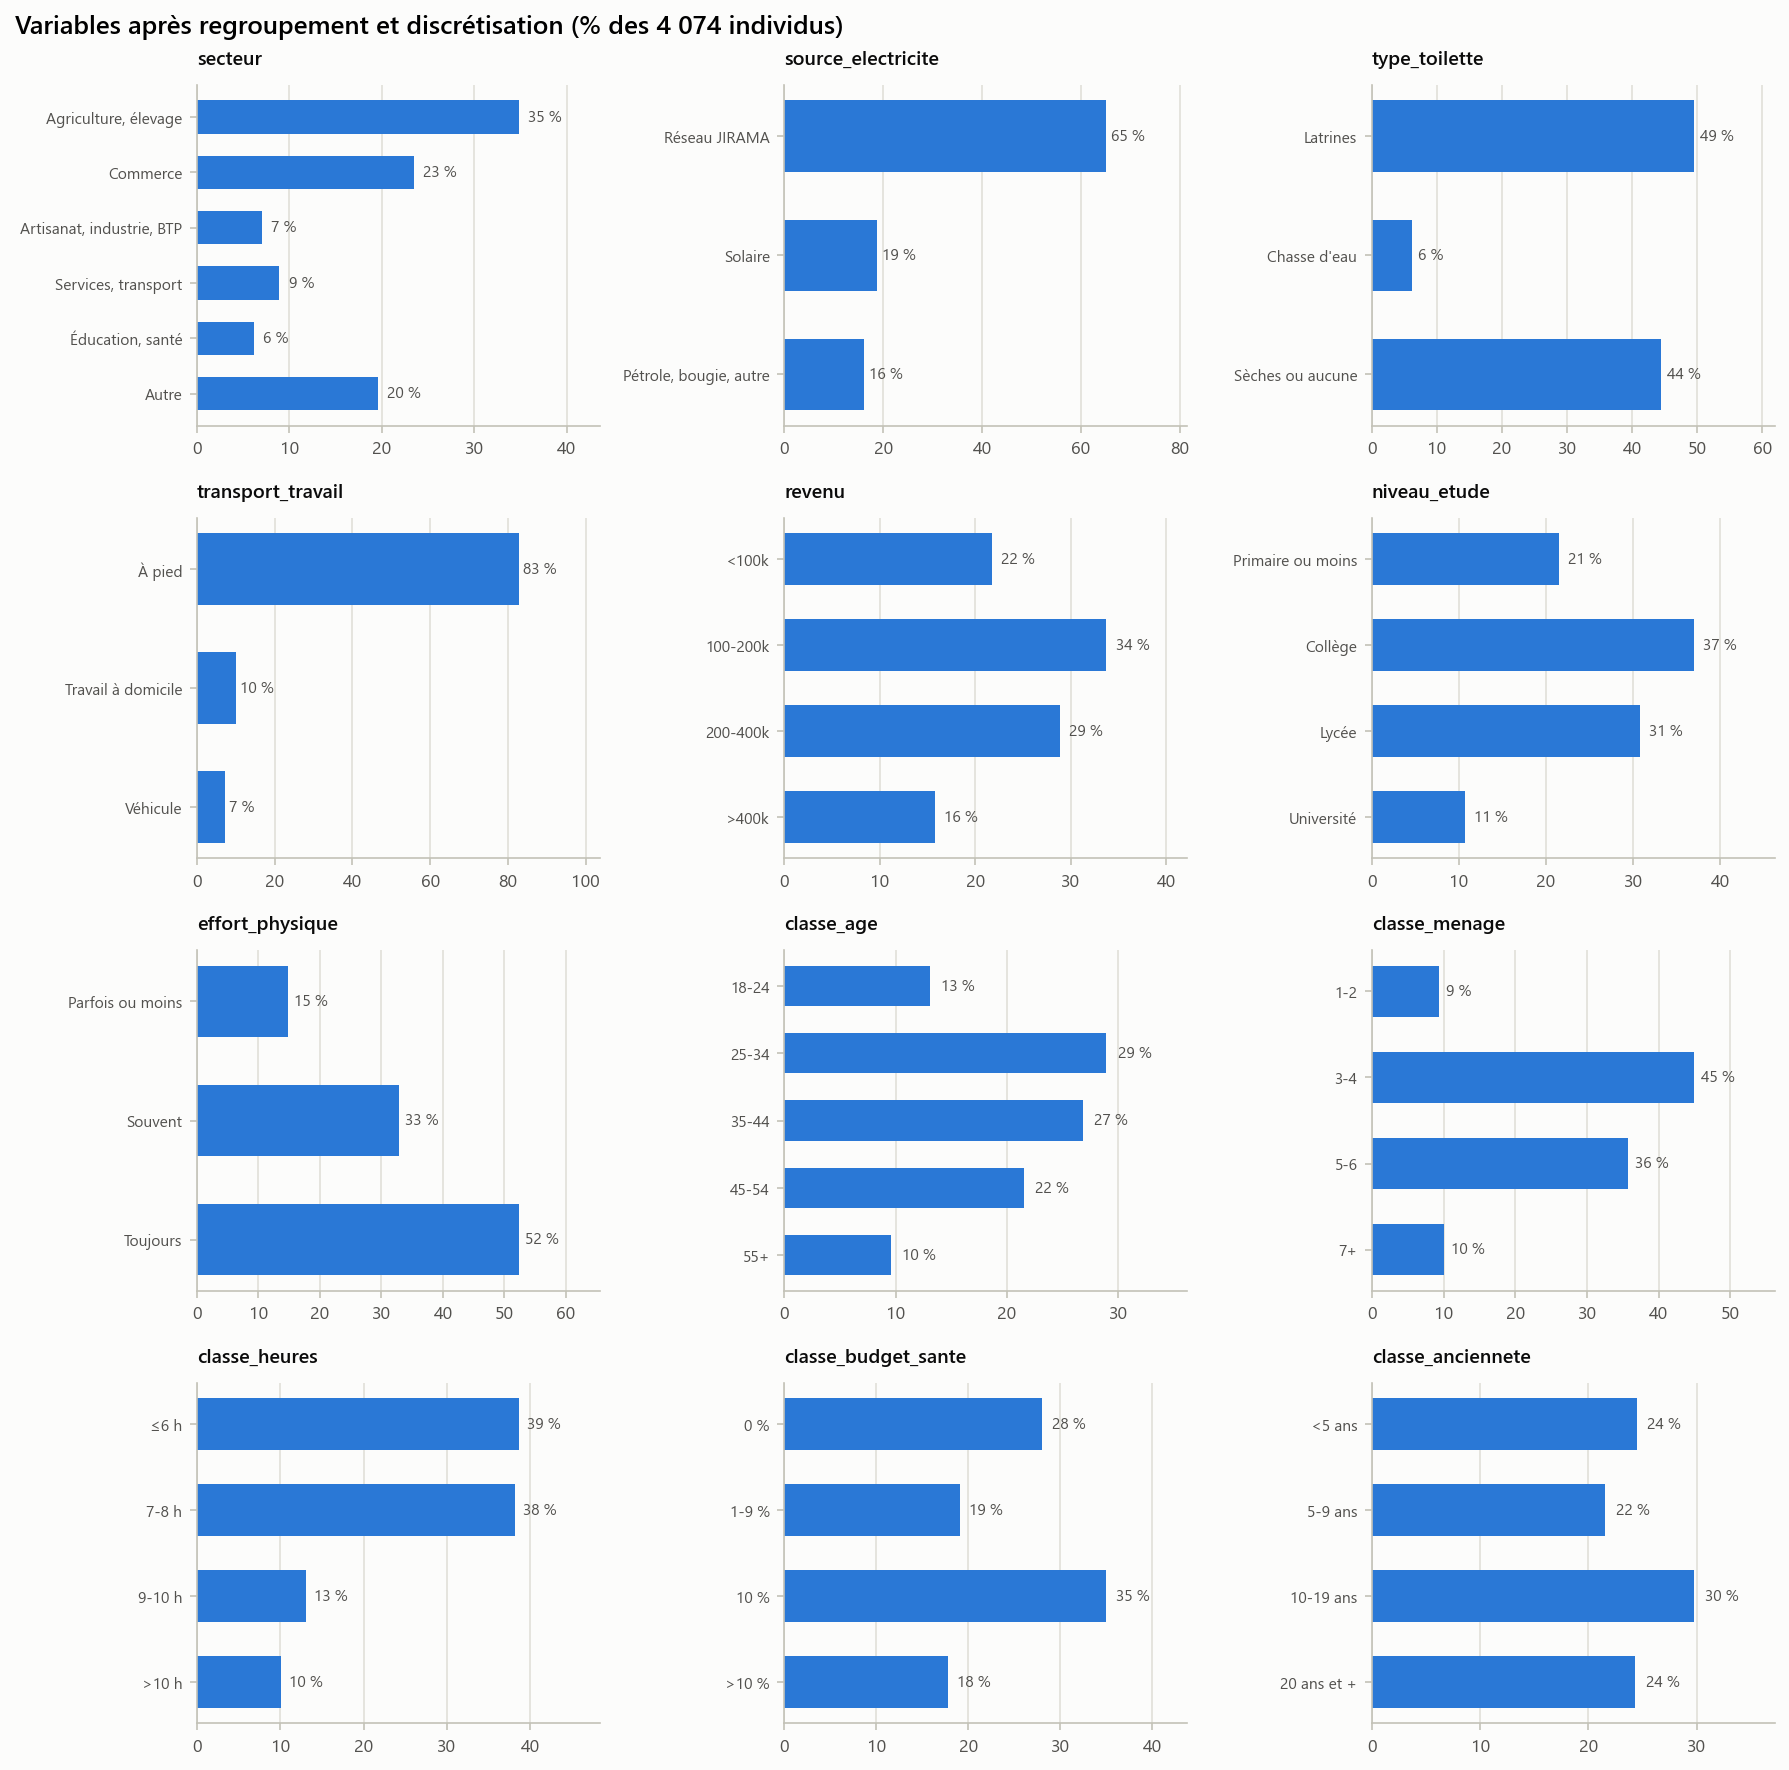

In [9]:
# Variables regroupées et classes : petits multiples
afficher = ["secteur", "source_electricite", "type_toilette", "transport_travail", "revenu",
            "niveau_etude", "effort_physique", "classe_age", "classe_menage", "classe_heures",
            "classe_budget_sante", "classe_anciennete"]
fig, axes = plt.subplots(4, 3, figsize=(12, 12))
for ax, v in zip(axes.ravel(), afficher):
    eff = final[v].value_counts().reindex(ORDRE_GROUPES[v])
    ax.barh(eff.index[::-1], 100 * eff.values[::-1] / n, color=BLEU, height=0.6)
    for y, val in enumerate(100 * eff.values[::-1] / n):
        ax.text(val + 1, y, f"{val:.0f} %", va="center", fontsize=7.5, color=C["encre2"])
    ax.set_xlim(0, max(100 * eff.max() / n * 1.25, 10))
    ax.set_title(v, fontsize=9.5)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=7.5)
fig.suptitle("Variables après regroupement et discrétisation (% des 4 074 individus)", x=0.01, ha="left")
fig.tight_layout()
o.sauver_figure(fig, RES, "variables_regroupees");

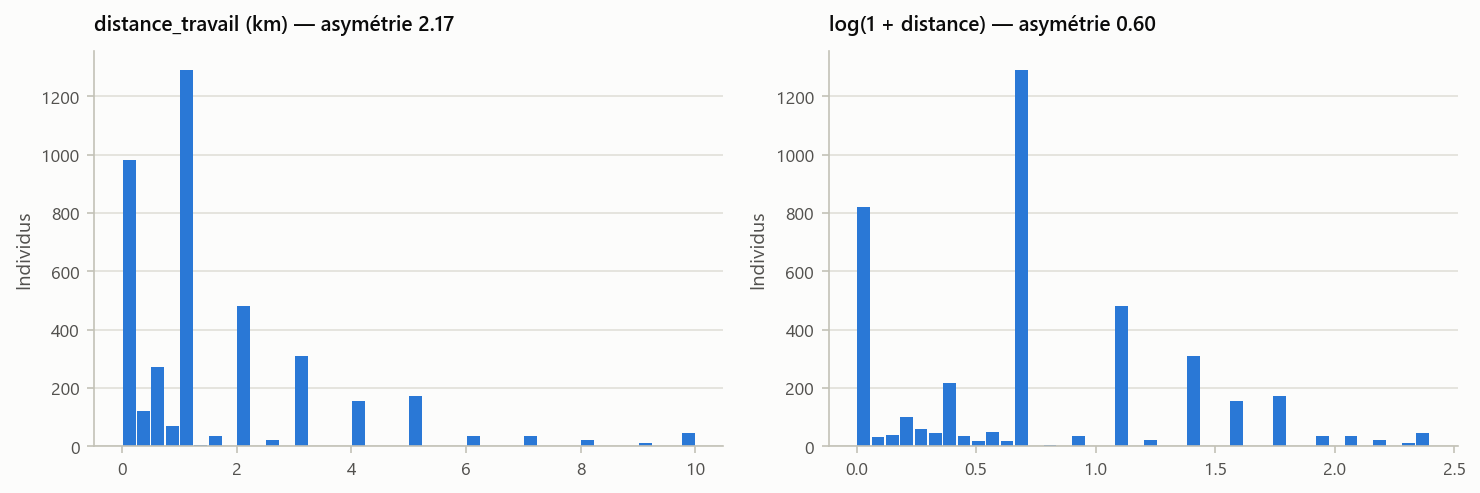


## Fichiers produits

- partie1_donnees\1.3_preparation\resultats\donnees_finales.csv
- partie1_donnees\1.3_preparation\resultats\donnees_finales.xlsx
- partie1_donnees\1.3_preparation\resultats\figures\transformation_distance.png
- partie1_donnees\1.3_preparation\resultats\figures\variables_regroupees.png
- partie1_donnees\1.3_preparation\resultats\journal.txt
- partie1_donnees\1.3_preparation\resultats\matrice_standardisee.csv
- partie1_donnees\1.3_preparation\resultats\tables\classes.csv
- partie1_donnees\1.3_preparation\resultats\tables\codage_et_standardisation.csv
- partie1_donnees\1.3_preparation\resultats\tables\evaluation_variables.csv
- partie1_donnees\1.3_preparation\resultats\tables\regroupements.csv
- partie1_donnees\1.3_preparation\resultats\tables\roles_variables.csv


In [10]:
# Effet de la transformation log sur la distance
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(df.distance_travail, bins=40, color=BLEU, rwidth=0.9)
axes[0].set_title(f"distance_travail (km) — asymétrie {df.distance_travail.skew():.2f}", fontsize=10)
axes[1].hist(final.log_distance_travail, bins=40, color=BLEU, rwidth=0.9)
axes[1].set_title(f"log(1 + distance) — asymétrie {final.log_distance_travail.skew():.2f}", fontsize=10)
for ax in axes:
    ax.set_ylabel("Individus")
fig.tight_layout()
o.sauver_figure(fig, RES, "transformation_distance")

log.section("Fichiers produits")
for f in sorted(RES.rglob("*.*")):
    log("-", f.relative_to(o.RACINE))
log.fermer();

---

Les tableaux complets sont dans `resultats/tables/`, les figures dans `resultats/figures/` et la sortie intégrale dans `resultats/journal.txt`. Commentaires et décisions : [README.md](README.md).